# Étape 11 : trois questions testées par régression logistique

L'étape 10 a montré des **associations** : l'équipe qui mène en or à 15 min gagne
plus souvent, celle qui prend la première tour aussi, le côté rouge gagne un peu plus.
Mais ces signaux sont très liés entre eux (or–XP 0,92, or–kills 0,90) : on ne sait pas
lequel compte vraiment. Ce notebook teste trois questions en **contrôlant** les autres
variables, avec des intervalles de confiance.

**La régression logistique en deux phrases.** Elle modélise la probabilité de victoire
du bleu : `log(p / (1 − p)) = b0 + b1·x1 + b2·x2 + …`. Chaque coefficient dit de combien
change la cote de victoire quand une variable augmente de 1 **à valeur égale des autres
variables du modèle** : c'est ce « à valeur égale » qu'une simple corrélation ne donne pas.

Les trois questions (partie 9 du notebook 01) :
1. À écart d'or égal, l'XP, les kills et les dragons ajoutent-ils quelque chose ?
2. La première tour garde-t-elle un effet une fois l'écart d'or à 15 min pris en compte ?
3. L'avantage du côté rouge tient-il en contrôlant le patch, et passe-t-il par les dragons ?

Plan :
1. Connexion et outils
2. Le jeu de données : une ligne par partie
3. Question 1 : l'or résume-t-il l'avance ?
4. Question 2 : la première tour
5. Question 3 : le côté rouge
6. Vérifications et limites
7. Conclusions

## 1. Connexion et outils

Avant de lancer : Docker Desktop ouvert et `docker compose start` fait.

On reprend `query()` du notebook 01. On ajoute **statsmodels**, la bibliothèque de
statistique de Python : elle donne, pour chaque coefficient, son erreur type,
son intervalle de confiance et sa p-valeur (scikit-learn, plus orienté prédiction,
ne les donne pas).

Les modèles s'écrivent avec des **formules** : `"blue_win ~ gold_k + xp_k"` se lit
« blue_win expliqué par gold_k et xp_k ». `C(patch)` dit que `patch` est une catégorie
(une colonne 0/1 par patch est créée automatiquement).

In [14]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
import statsmodels.formula.api as smf
from dotenv import load_dotenv
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Le notebook tourne depuis notebooks/ : la racine du projet est le dossier parent.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(ROOT / ".env")
DATABASE_URL = os.environ["DATABASE_URL"]


def query(sql, params=None):
    """Exécute une requête SELECT et renvoie le résultat en DataFrame."""
    with psycopg.connect(DATABASE_URL) as conn:
        cur = conn.execute(sql, params)
        columns = [col.name for col in cur.description]
        return pd.DataFrame(cur.fetchall(), columns=columns)


plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:.3f}".format)

query("SELECT count(*) AS parties FROM matches")

,parties
0,4907


Trois petits outils, utilisés pour toutes les questions :

- `fit(formula)` ajuste une régression logistique sur le jeu de données.
- `odds_table(model)` présente les résultats lisiblement. Un coefficient brut
  (en « log-cote ») n'est pas parlant ; on affiche son exponentielle, l'**odds ratio** :
  1,25 veut dire « la cote de victoire est multipliée par 1,25 » (+25 %), 1 veut dire
  « aucun effet ». Si l'intervalle de confiance à 95 % contient 1, l'effet n'est pas établi.
- `lr_test(petit, grand)` compare deux modèles **emboîtés** (le grand contient toutes les
  variables du petit, plus d'autres) avec le test du rapport de vraisemblance : les variables
  ajoutées améliorent-elles le modèle plus que le hasard ne le ferait ? Une p-valeur
  sous 0,05 dit oui.

In [15]:
def fit(formula, data=None):
    """Régression logistique (maximum de vraisemblance) sur le jeu de données."""
    return smf.logit(formula, data=df if data is None else data).fit(disp=False)


def odds_table(model):
    """Coefficients en odds ratios, avec IC 95 % et p-valeurs."""
    ci = model.conf_int()
    return pd.DataFrame({
        "coef": model.params,
        "odds_ratio": np.exp(model.params),
        "or_ic_bas": np.exp(ci[0]),
        "or_ic_haut": np.exp(ci[1]),
        "p_valeur": model.pvalues,
    })


def lr_test(small, big):
    """Test du rapport de vraisemblance entre deux modèles emboîtés."""
    stat = 2 * (big.llf - small.llf)
    dof = big.df_model - small.df_model
    return pd.Series({"statistique": stat, "ddl": dof, "p_valeur": stats.chi2.sf(stat, dof)})


def logistic(x):
    """Log-cote -> probabilité."""
    return 1 / (1 + np.exp(-x))

## 2. Le jeu de données : une ligne par partie

Même construction qu'à l'étape 10 : des **écarts bleu moins rouge** à 15 min, et la cible
`blue_win` (1 si le bleu gagne). Une ligne par partie, vue du côté bleu : prendre aussi
la ligne du rouge doublerait les données sans rien apporter (c'est la même partie,
retournée) et rendrait les lignes dépendantes deux à deux.

Conséquence utile : comme tout est « bleu − rouge », la **constante** du modèle
(`Intercept`) est la log-cote de victoire du bleu quand tous les écarts valent 0.
C'est elle qui mesure l'avantage de côté (question 3).

Changements par rapport à l'étape 10 :
- `towers_diff` ne compte plus que les tours (`building_type = 'TOWER_BUILDING'`),
  sans les inhibiteurs ;
- `first_tower15` : quelle équipe a pris la première tour **avant 15 min**
  (`bleu`, `rouge` ou `aucune`). On n'utilise pas `teams.first_tower`, qui porte sur
  toute la partie : une tour prise à 25 min n'a rien à faire dans un état à 15 min ;
- `patch` (ex. `16.19`), pour contrôler l'équilibre du jeu ;
- filtres : patchs 16.14 à 16.21 (98 % des parties) et parties qui ont une minute 15.

L'or et l'XP sont divisés par 1 000 (`gold_k`, `xp_k`) : un coefficient « pour 1 or »
serait minuscule et illisible ; « pour 1 000 or » se lit directement.

In [16]:
PATCH_MIN, PATCH_MAX = 14, 21  # patchs 16.14 à 16.21

df = query("""
    WITH frames15 AS (
        SELECT f.match_id,
               sum(CASE WHEN p.team_id = 100 THEN 1 ELSE -1 END * f.total_gold) AS gold_diff,
               sum(CASE WHEN p.team_id = 100 THEN 1 ELSE -1 END * f.xp) AS xp_diff,
               sum(CASE WHEN p.team_id = 100 THEN 1 ELSE -1 END
                   * (f.minions_killed + f.jungle_minions_killed)) AS cs_diff
        FROM participant_frames f
        JOIN participants p USING (match_id, participant_id)
        WHERE f.minute = 15
        GROUP BY f.match_id
    ),
    events15 AS (
        SELECT match_id,
               sum(CASE WHEN killer_team_id = 100 THEN 1 ELSE -1 END)
                   FILTER (WHERE event_type = 'CHAMPION_KILL') AS kills_diff,
               sum(CASE WHEN killer_team_id = 100 THEN 1 ELSE -1 END)
                   FILTER (WHERE building_type = 'TOWER_BUILDING') AS towers_diff,
               sum(CASE WHEN killer_team_id = 100 THEN 1 ELSE -1 END)
                   FILTER (WHERE event_type = 'TURRET_PLATE_DESTROYED') AS plates_diff,
               sum(CASE WHEN killer_team_id = 100 THEN 1 ELSE -1 END)
                   FILTER (WHERE monster_type = 'DRAGON') AS dragons_diff
        FROM events
        WHERE timestamp_ms < 15 * 60 * 1000
          AND killer_team_id IS NOT NULL
        GROUP BY match_id
    ),
    first_tower AS (
        -- DISTINCT ON garde, pour chaque partie, la 1re ligne selon ORDER BY : la tour la plus tôt
        SELECT DISTINCT ON (match_id) match_id, killer_team_id
        FROM events
        WHERE building_type = 'TOWER_BUILDING'
          AND timestamp_ms < 15 * 60 * 1000
          AND killer_team_id IS NOT NULL
        ORDER BY match_id, timestamp_ms
    )
    SELECT f.match_id,
           split_part(m.game_version, '.', 1) || '.' || split_part(m.game_version, '.', 2) AS patch,
           f.gold_diff, f.xp_diff, f.cs_diff,
           coalesce(e.kills_diff, 0)   AS kills_diff,
           coalesce(e.towers_diff, 0)  AS towers_diff,
           coalesce(e.plates_diff, 0)  AS plates_diff,
           coalesce(e.dragons_diff, 0) AS dragons_diff,
           CASE ft.killer_team_id WHEN 100 THEN 'bleu' WHEN 200 THEN 'rouge' ELSE 'aucune' END
               AS first_tower15,
           t.win::int AS blue_win
    FROM frames15 f
    JOIN matches m USING (match_id)
    JOIN teams t ON t.match_id = f.match_id AND t.team_id = 100
    LEFT JOIN events15 e ON e.match_id = f.match_id
    LEFT JOIN first_tower ft ON ft.match_id = f.match_id
    WHERE split_part(m.game_version, '.', 1) = '16'
      AND split_part(m.game_version, '.', 2)::int BETWEEN %(lo)s AND %(hi)s
""", {"lo": PATCH_MIN, "hi": PATCH_MAX})

INT_COLS = ["gold_diff", "xp_diff", "cs_diff", "kills_diff", "towers_diff",
            "plates_diff", "dragons_diff", "blue_win"]
df[INT_COLS] = df[INT_COLS].astype(int)
df["gold_k"] = df["gold_diff"] / 1000
df["xp_k"] = df["xp_diff"] / 1000
df["cs_diff_10"] = df["cs_diff"] / 10  # CS par paquets de 10

total = query("SELECT count(*) AS n FROM matches")["n"][0]
print(f"{len(df)} parties gardées sur {total} ({total - len(df)} exclues : "
      "autre patch ou pas de minute 15).")
print(f"Victoires du bleu : {df['blue_win'].mean():.1%}")
df["first_tower15"].value_counts().to_frame("parties")

4762 parties gardées sur 4907 (145 exclues : autre patch ou pas de minute 15).
Victoires du bleu : 48.5%


,parties
first_tower15,
bleu,1924
rouge,1830
aucune,1008


## 3. Question 1 : l'or résume-t-il l'avance ?

L'étape 10 a trouvé que l'or, l'XP et les kills sont presque la même information
(corrélations 0,90 et plus). La question : **une fois l'écart d'or connu, l'XP, les kills
et les dragons apportent-ils encore quelque chose ?** Si non, l'or suffit à résumer
l'avance à 15 min ; si oui, certaines formes d'avance comptent plus que l'or qu'elles rapportent.

Méthode : deux modèles emboîtés.
- `m_gold` : l'écart d'or seul ;
- `m_q1` : l'or + l'XP + les kills + les dragons.

Puis le test du rapport de vraisemblance entre les deux, et la lecture des coefficients.

In [17]:
m_gold = fit("blue_win ~ gold_k")
odds_table(m_gold)

,coef,odds_ratio,or_ic_bas,or_ic_haut,p_valeur
Intercept,-0.101,0.904,0.846,0.967,0.003
gold_k,0.362,1.436,1.403,1.469,0.000


Lecture : l'odds ratio de `gold_k` dit par combien la cote de victoire du bleu est
multipliée pour chaque 1 000 or d'avance à 15 min.

Avant d'aller plus loin, on vérifie que le modèle **colle aux données** : la courbe en S
prédite par `m_gold` doit passer par les taux de victoire observés par décile
(les points de l'étape 10). Si elle s'en écartait, la forme « logistique » serait mauvaise.

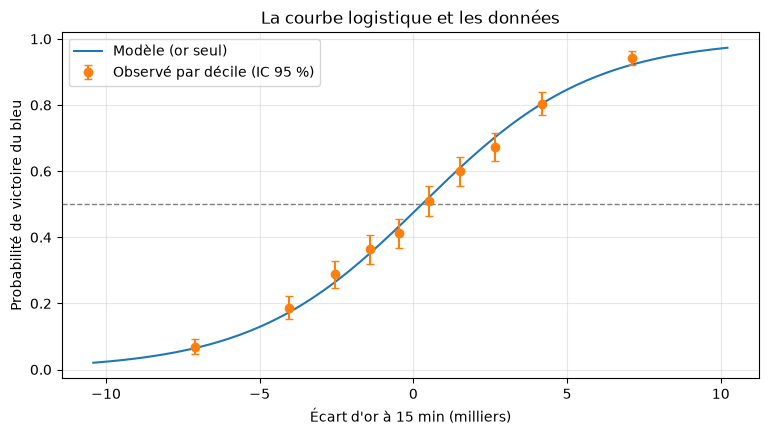

Écart de     0 or : probabilité de victoire du bleu 47.5%
Écart de  1000 or : probabilité de victoire du bleu 56.5%
Écart de  2000 or : probabilité de victoire du bleu 65.1%
Écart de  4000 or : probabilité de victoire du bleu 79.3%


In [18]:
deciles = df.groupby(pd.qcut(df["gold_diff"], 10), observed=True).agg(
    x=("gold_k", "mean"), p=("blue_win", "mean"), n=("blue_win", "size"))
half = 1.96 * np.sqrt(deciles["p"] * (1 - deciles["p"]) / deciles["n"])

grid = pd.DataFrame({"gold_k": np.linspace(df["gold_k"].quantile(0.005),
                                           df["gold_k"].quantile(0.995), 200)})
fig, ax = plt.subplots()
ax.plot(grid["gold_k"], m_gold.predict(grid), label="Modèle (or seul)")
ax.errorbar(deciles["x"], deciles["p"], yerr=half, fmt="o", capsize=3,
            label="Observé par décile (IC 95 %)")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Écart d'or à 15 min (milliers)")
ax.set_ylabel("Probabilité de victoire du bleu")
ax.set_title("La courbe logistique et les données")
ax.legend()
plt.show()

for g in [0, 1, 2, 4]:
    p = m_gold.predict(pd.DataFrame({"gold_k": [g]}))[0]
    print(f"Écart de {g * 1000:>5} or : probabilité de victoire du bleu {p:.1%}")

Maintenant le modèle avec les autres signaux. Point à surveiller : quand on ajoute des
variables très liées à l'or, le coefficient de l'or **baisse**, parce que l'information
qu'il portait seul est maintenant partagée. Ce n'est pas une erreur, c'est le sens même de
« à valeur égale des autres variables ».

Le **VIF** (facteur d'inflation de la variance) mesure ce partage : il dit combien
l'incertitude sur un coefficient est gonflée parce que sa variable est prévisible à partir
des autres. Repère courant : au-delà de 5 à 10, les coefficients individuels deviennent
instables (larges intervalles), même si le modèle dans son ensemble reste bon.

In [19]:
m_q1 = fit("blue_win ~ gold_k + xp_k + kills_diff + dragons_diff")
display(odds_table(m_q1))

X = m_q1.model.exog  # la matrice des variables, avec la colonne de la constante
names = m_q1.model.exog_names
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])],
                index=names[1:], name="VIF")
display(vif.to_frame())

print("Test du rapport de vraisemblance, or seul -> or + XP + kills + dragons :")
display(lr_test(m_gold, m_q1).to_frame("résultat"))
print(f"Pseudo-R² de McFadden : or seul {m_gold.prsquared:.3f}, avec les autres {m_q1.prsquared:.3f}")
print(f"AIC (plus petit = meilleur) : or seul {m_gold.aic:.0f}, avec les autres {m_q1.aic:.0f}")

,coef,odds_ratio,or_ic_bas,or_ic_haut,p_valeur
Intercept,-0.046,0.955,0.892,1.023,0.191
gold_k,0.264,1.302,1.232,1.376,0.000
xp_k,0.096,1.100,1.047,1.156,0.000
kills_diff,-0.009,0.991,0.969,1.014,0.447
dragons_diff,0.263,1.301,1.233,1.373,0.000


,VIF
gold_k,9.769
xp_k,6.618
kills_diff,5.778
dragons_diff,1.275


Test du rapport de vraisemblance, or seul -> or + XP + kills + dragons :


,résultat
statistique,109.429
ddl,3.000
p_valeur,0.000


Pseudo-R² de McFadden : or seul 0.225, avec les autres 0.242
AIC (plus petit = meilleur) : or seul 5114, avec les autres 5010


Pour voir **ce que chaque variable ajoute seule** à l'or, on ajoute les variables une par
une et on fait un test à chaque fois (même logique, en plus détaillé). On regarde aussi
comment le coefficient de l'or bouge : c'est la « stabilité des coefficients » notée
à l'étape 10.

In [20]:
rows = []
for extra in ["xp_k", "kills_diff", "dragons_diff", "towers_diff", "plates_diff", "cs_diff_10"]:
    m = fit(f"blue_win ~ gold_k + {extra}")
    test = lr_test(m_gold, m)
    rows.append({
        "variable_ajoutée": extra,
        "or_ratio_variable": np.exp(m.params[extra]),
        "ic_bas": np.exp(m.conf_int().loc[extra, 0]),
        "ic_haut": np.exp(m.conf_int().loc[extra, 1]),
        "or_ratio_gold_k": np.exp(m.params["gold_k"]),
        "p_valeur_lr": test["p_valeur"],
    })
pd.DataFrame(rows).set_index("variable_ajoutée")

,or_ratio_variable,ic_bas,ic_haut,or_ratio_gold_k,p_valeur_lr
variable_ajoutée,,,,,
xp_k,1.102,1.049,1.157,1.328,0.000
kills_diff,1.018,0.996,1.041,1.394,0.110
dragons_diff,1.297,1.231,1.367,1.387,0.000
towers_diff,0.938,0.867,1.016,1.462,0.116
plates_diff,0.994,0.975,1.013,1.448,0.551
cs_diff_10,1.004,0.985,1.023,1.430,0.670


## 4. Question 2 : la première tour

À l'étape 10, l'équipe qui prend la première tour gagne 68,5 % de ses parties. Mais elle est
souvent déjà devant : on ne sait pas si c'est la tour qui aide, ou l'avance qui fait
à la fois prendre la tour et gagner. On compare donc :
- `m_ft` : la première tour avant 15 min seule (référence : `aucune` tour avant 15 min) ;
- `m_ft_gold` : la première tour **+ l'écart d'or à 15 min**.

Si l'odds ratio de la première tour fond quand on ajoute l'or, la tour était surtout un
signe de l'avance ; s'il reste nettement au-dessus de 1, elle porte un effet propre.

Subtilité à savoir expliquer : une tour rapporte de l'or à l'équipe qui la prend, donc
l'écart d'or à 15 min **contient déjà une partie de l'effet de la tour**. Contrôler par
l'or mesure ce que la tour apporte **au-delà de l'or qu'elle a rapporté** (position sur
la carte, accès à la jungle adverse, plaques suivantes…). C'est la question intéressante,
mais il faut le dire en présentant le résultat.

In [21]:
FT = "C(first_tower15, Treatment('aucune'))"
m_ft = fit(f"blue_win ~ {FT}")
m_ft_gold = fit(f"blue_win ~ {FT} + gold_k")

compare = pd.concat({"sans contrôle": odds_table(m_ft), "avec l'or": odds_table(m_ft_gold)}, axis=1)
compare = compare.loc[:, (slice(None), ["odds_ratio", "or_ic_bas", "or_ic_haut", "p_valeur"])]
compare.index = compare.index.str.replace(f"{FT}", "première tour ", regex=False)
compare

sans contrôle                                \
                           odds_ratio or_ic_bas or_ic_haut p_valeur   
Intercept                       0.853     0.754      0.965    0.012   
première tour [T.bleu]          2.525     2.159      2.954    0.000   
première tour [T.rouge]         0.478     0.407      0.561    0.000   
gold_k                            NaN       NaN        NaN      NaN   

                         avec l'or                                
                        odds_ratio or_ic_bas or_ic_haut p_valeur  
Intercept                    0.905     0.792      1.035    0.144  
première tour [T.bleu]       0.942     0.785      1.130    0.521  
première tour [T.rouge]      1.060     0.885      1.270    0.525  
gold_k                       1.451     1.410      1.492    0.000

Les odds ratios se lisent mal pour un public : on les traduit en **probabilités**.
Ci-dessous, la probabilité de victoire du bleu prédite par `m_ft_gold` pour un écart d'or
fixé, selon qui a pris la première tour. L'écart entre les lignes, à or égal,
est l'effet propre de la tour.

In [22]:
rows = []
for gold in [-2, 0, 2]:
    for ft in ["rouge", "aucune", "bleu"]:
        p = m_ft_gold.predict(pd.DataFrame({"gold_k": [gold], "first_tower15": [ft]}))[0]
        rows.append({"écart d'or": gold * 1000, "première tour": ft, "victoire du bleu": p})
pd.DataFrame(rows).pivot(index="écart d'or", columns="première tour", values="victoire du bleu")[
    ["rouge", "aucune", "bleu"]]

première tour,rouge,aucune,bleu
écart d'or,,,
-2000,0.313,0.301,0.288
0,0.490,0.475,0.460
2000,0.669,0.656,0.642


## 5. Question 3 : le côté rouge

Le bleu gagne 48,3 % des parties à l'étape 10. Trois questions en une :
1. Est-ce que ça tient **en contrôlant le patch** ? Si un patch très favorable au rouge
   pesait lourd dans l'échantillon, l'avantage pourrait venir de lui seul.
2. L'avantage varie-t-il **d'un patch à l'autre** ?
3. **Passe-t-il par les dragons ?** Le rouge prend plus de dragons avant 15 min. Si on
   ajoute l'écart de dragons et que l'avantage rouge disparaît, il passait (au moins
   en partie) par eux : on parle de **variable médiatrice**.

Rappel : la constante (`Intercept`) est la log-cote de victoire du bleu quand tous les
écarts valent 0. On la suit d'un modèle à l'autre et on la traduit en probabilité.

Pour le patch, on utilise un codage « somme » (`C(patch, Sum)`) : la constante devient
la **moyenne sur les patchs** (chaque patch compte pareil) au lieu de la valeur d'un patch
de référence choisi arbitrairement.

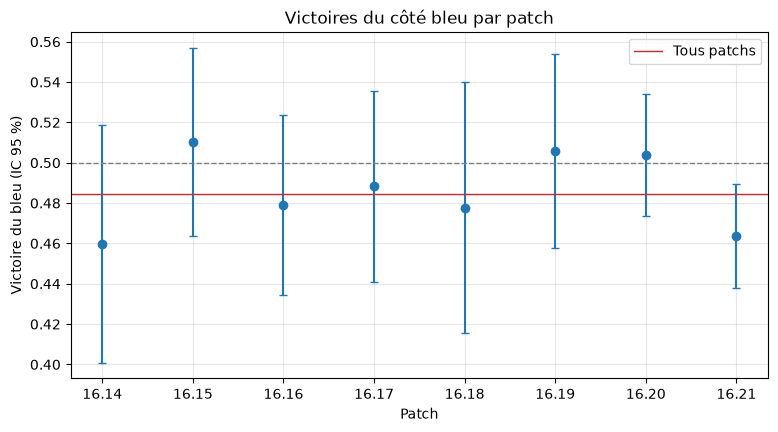

,n,p,half
patch,,,
16.14,274,0.460,0.059
16.15,439,0.510,0.047
16.16,478,0.479,0.045
16.17,428,0.488,0.047
16.18,247,0.478,0.062
16.19,415,0.506,0.048
16.20,1044,0.504,0.030
16.21,1437,0.463,0.026


In [23]:
side = (df.groupby("patch")["blue_win"].agg(n="size", p="mean")
        .assign(half=lambda t: 1.96 * np.sqrt(t["p"] * (1 - t["p"]) / t["n"])))
side["_mineur"] = side.index.str.split(".").str[1].astype(int)
side = side.sort_values("_mineur").drop(columns="_mineur")

fig, ax = plt.subplots()
ax.errorbar(side.index, side["p"], yerr=side["half"], fmt="o", capsize=3)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.axhline(df["blue_win"].mean(), color="tab:red", linewidth=1, label="Tous patchs")
ax.set_xlabel("Patch")
ax.set_ylabel("Victoire du bleu (IC 95 %)")
ax.set_title("Victoires du côté bleu par patch")
ax.legend()
plt.show()
side

In [24]:
side_models = {
    "1. rien": fit("blue_win ~ 1"),
    "2. patch": fit("blue_win ~ C(patch, Sum)"),
    "3. patch + dragons": fit("blue_win ~ C(patch, Sum) + dragons_diff"),
    "4. patch + état complet à 15 min": fit(
        "blue_win ~ C(patch, Sum) + gold_k + xp_k + kills_diff + dragons_diff"
        " + towers_diff + plates_diff"),
}

rows = []
for name, m in side_models.items():
    lo, hi = m.conf_int().loc["Intercept"]
    rows.append({"modèle": name,
                 "constante": m.params["Intercept"],
                 "p_valeur": m.pvalues["Intercept"],
                 "victoire_bleu": logistic(m.params["Intercept"]),
                 "ic_bas": logistic(lo), "ic_haut": logistic(hi)})
display(pd.DataFrame(rows).set_index("modèle"))

print("Le patch change-t-il le taux de victoire du bleu ? (rien -> patch)")
display(lr_test(side_models["1. rien"], side_models["2. patch"]).to_frame("résultat"))
print("Odds ratio des dragons dans le modèle 3 :",
      odds_table(side_models["3. patch + dragons"]).loc["dragons_diff", ["odds_ratio", "or_ic_bas", "or_ic_haut"]].round(3).to_dict())

,constante,p_valeur,victoire_bleu,ic_bas,ic_haut
modèle,,,,,
1. rien,-0.061,0.034,0.485,0.470,0.499
2. patch,-0.056,0.101,0.486,0.469,0.503
3. patch + dragons,0.036,0.316,0.509,0.491,0.527
4. patch + état complet à 15 min,-0.044,0.281,0.489,0.469,0.509


Le patch change-t-il le taux de victoire du bleu ? (rien -> patch)


,résultat
statistique,6.837
ddl,7.000
p_valeur,0.446


Odds ratio des dragons dans le modèle 3 : {'odds_ratio': 1.705, 'or_ic_bas': 1.628, 'or_ic_haut': 1.786}


Lecture du tableau : la colonne `victoire_bleu` est la probabilité de victoire du bleu
« toutes choses égales » dans chaque modèle (patch moyen, écarts nuls). Si elle reste
sous 50 % avec un intervalle qui exclut 50 % dans le modèle 2, l'avantage rouge ne vient
pas d'un patch particulier. Si elle remonte vers 50 % dans le modèle 3, une partie de
l'avantage rouge passe par les dragons.

Attention à l'interprétation du modèle 4 : contrôler par **tout** l'état à 15 min répond
à une autre question (« à état de partie identique à 15 min, le côté compte-t-il
encore ? »). Une partie de l'avantage de côté s'est peut-être déjà transformée en or ou
en kills avant 15 min ; le modèle 4 ne la voit plus.

## 6. Vérifications et limites

**Le modèle complet.** Toutes les variables ensemble, pour voir l'ensemble des effets
« à valeur égale ». À lire avec les VIF : les coefficients de variables très liées
(or, XP, kills) sont instables individuellement.

In [25]:
m_full = fit("blue_win ~ gold_k + xp_k + kills_diff + dragons_diff + towers_diff"
             " + plates_diff + cs_diff_10 + C(patch, Sum)")
full = odds_table(m_full)
display(full[~full.index.str.startswith("C(patch")])
print(f"Pseudo-R² : {m_full.prsquared:.3f} ; parties : {int(m_full.nobs)}")

,coef,odds_ratio,or_ic_bas,or_ic_haut,p_valeur
Intercept,-0.043,0.958,0.884,1.038,0.293
gold_k,0.285,1.329,1.228,1.439,0.000
xp_k,0.103,1.108,1.050,1.170,0.000
kills_diff,-0.017,0.983,0.955,1.011,0.234
dragons_diff,0.265,1.303,1.235,1.375,0.000
towers_diff,-0.062,0.940,0.843,1.049,0.269
plates_diff,0.012,1.012,0.985,1.040,0.393
cs_diff_10,-0.012,0.988,0.964,1.013,0.358


Pseudo-R² : 0.243 ; parties : 4762


**Erreurs types robustes.** Les intervalles de confiance ci-dessus supposent que le
modèle est bien spécifié. On refait le modèle complet avec des erreurs types
**robustes** (dites « sandwich », HC1), qui ne font pas cette hypothèse. Un rapport
proche de 1 veut dire que les intervalles ne dépendent pas de cette hypothèse.

Ce que ce contrôle ne couvre pas : la dépendance entre parties. 21 % des places sont
occupées par un joueur vu plusieurs fois, donc les parties ne sont pas tout à fait
indépendantes. La corriger exactement demanderait de regrouper les parties par joueur,
compliqué quand chaque partie a 10 joueurs. Comme 79 % des places sont des joueurs vus
une seule fois, l'effet attendu est faible : on le cite comme limite.

In [26]:
m_full_hc = smf.logit(m_full.model.formula, data=df).fit(disp=False, cov_type="HC1")
ratio = (m_full_hc.bse / m_full.bse).rename("erreur_type_robuste / classique")
ratio[~ratio.index.str.startswith("C(patch")].to_frame()

,erreur_type_robuste / classique
Intercept,0.998
gold_k,1.003
xp_k,1.022
kills_diff,0.995
dragons_diff,1.004
towers_diff,1.006
plates_diff,1.000
cs_diff_10,1.021


**Limites à garder en tête (et à savoir dire en entretien) :**
- **Association, pas causalité.** Contrôler par l'or rapproche d'un « effet propre »,
  mais d'autres choses non mesurées (niveau des joueurs, composition des équipes)
  influencent à la fois l'état à 15 min et la victoire.
- **Variables très corrélées.** Les coefficients individuels de l'or, de l'XP et des kills
  sont à lire ensemble ; les VIF disent à quel point.
- **Échantillon.** Une seule région (EUW), une collecte boule de neige partie d'un joueur
  (niveau pas forcément représentatif), environ 4 800 parties.
- **Tests multiples.** On fait une quinzaine de tests : à 5 % de risque chacun, un
  « significatif » par hasard est possible. Les effets avec une p-valeur très petite
  (bien sous 0,001) sont solides ; ceux juste sous 0,05 sont à prendre avec prudence.
- **Pas de validation hors échantillon.** Ici on explique, on ne prédit pas. Mesurer la
  qualité de prédiction (validation croisée, calibration) est le travail de l'étape 12.

## 7. Conclusions

*Écrit le 31 oct. 2026 à partir de l'exécution sur la base complète : 4 762 parties gardées (patchs 16.14 à 16.21, au moins 15 min) sur 4 907.*

**Le modèle colle aux données.** Avec l'écart d'or seul, la courbe logistique passe dans l'intervalle de confiance des 10 déciles observés. Chaque 1 000 or d'avance à 15 min multiplie la cote de victoire par 1,44 (IC 95 % : 1,40 à 1,47). Probabilité de victoire du bleu : 47,5 % à écart nul, 56,5 % à +1 000 or, 65,1 % à +2 000, 79,3 % à +4 000.

**Question 1 : l'or ne résume pas tout, mais presque.**
- Ajouter l'XP, les kills et les dragons améliore nettement le modèle (rapport de vraisemblance 109 pour 3 ddl, p < 0,001 ; AIC 5 114 → 5 010 ; pseudo-R² 0,225 → 0,242).
- À or égal, **les dragons comptent** : odds ratio 1,30 par dragon d'avance (IC 1,23 à 1,37). Dans ce modèle, un dragon d'avance pèse à peu près autant que 1 000 or d'avance (coefficients 0,263 et 0,264). Leur effet (bonus permanents, progression vers l'âme) ne passe pas par l'or.
- À or égal, **l'XP ajoute un peu** : 1,10 pour 1 000 XP d'avance (IC 1,05 à 1,16).
- À or égal, **les kills n'ajoutent rien** (0,99, IC 0,97 à 1,01) : leur effet passe par l'or qu'ils rapportent. Même chose pour les tours, les plaques et le CS (p-valeurs 0,12 à 0,67).
- Or, XP et kills partagent beaucoup d'information (VIF 9,8 / 6,6 / 5,8) : leurs coefficients sont à lire ensemble, pas un par un.

**Question 2 : la première tour n'a pas d'effet propre.** Sans contrôle, la cote du bleu est multipliée par 2,53 quand il prend la première tour avant 15 min (par 0,48 quand c'est le rouge). À écart d'or égal, l'effet disparaît : 0,94 (IC 0,79 à 1,13) et 1,06 (IC 0,89 à 1,27). La première tour est un **signe** de l'avance, pas une cause supplémentaire de victoire. Comme l'or de la tour est compris dans l'écart d'or, le résultat exact est : la tour n'apporte rien au-delà de l'or qu'elle rapporte.

**Question 3 : l'avantage rouge est faible et passe par les dragons.**
- Sans contrôle, le bleu gagne 48,5 % des parties (IC 47,0 à 49,9 ; p = 0,03).
- Le patch ne change pas ce taux (rapport de vraisemblance p = 0,45). En le contrôlant, on obtient 48,6 % (IC 46,9 à 50,3 ; p = 0,10) : l'avantage rouge devient incertain.
- À écart de dragons égal, le bleu remonte à 50,9 % (IC 49,1 à 52,7) : **il n'y a plus d'avantage de côté**. Ce qui reste d'avantage rouge s'explique par les dragons, que le rouge prend plus souvent avant 15 min.

**Vérifications.** Le modèle complet donne les mêmes conclusions : or 1,33, XP 1,11, dragons 1,30, rien pour les kills, les tours, les plaques et le CS (pseudo-R² 0,243). Les erreurs types robustes diffèrent de moins de 3 % des erreurs classiques.

**Limites.** Ce sont des associations, pas des causes : le niveau des joueurs et les compositions ne sont pas mesurés. Les parties ne sont pas tout à fait indépendantes (21 % des places = joueurs vus plusieurs fois). Une quinzaine de tests ont été faits ; les conclusions ci-dessus reposent sur des p-valeurs très petites (sous 0,001), sauf l'avantage rouge, qui reste fragile.

**Pour l'étape 12 (modèle à 15 min).** Variables à garder : or, XP, dragons. Les kills, tours, plaques et CS n'apportent rien de plus en régression logistique ; LightGBM dira s'ils servent de façon non linéaire. Le côté et le patch peuvent rester comme contrôles, avec un effet attendu proche de zéro.